In [1]:
# Supply Chain & Logistics Performance Analytics
# Step 1: import the libraries we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# Same look for every chart
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
main_color = "#1f4e79"
good_color = "#2e8b57"
bad_color = "#c0392b"
warn_color = "#e08e0b"

In [2]:
# BUSINESS PROBLEM
# A large retail and distribution company works with many suppliers, warehouses and
# delivery locations. Management sees shortages, excess stock, late deliveries, rising
# transport costs and uneven supplier performance, but has no single view of them.
#
# CORE OBJECTIVES
# 1. Measure delivery reliability (on-time %, delay days, order lead time)
# 2. Score suppliers on lead time, punctuality and procurement spend
# 3. Compare warehouse (distribution centre) load, capacity and handling cost
# 4. Find the most cost-effective transport mode and track freight cost month by month
# 5. Show which products and regions have rising demand and which have delays
# 6. Turn the findings into actions that cut cost and improve delivery
#
# DATA USED (two public Kaggle datasets, both real supply chain records)
# Part A: SCMS Delivery History (10,324 shipment lines, 2006 to 2015)
#         suppliers, purchase orders, scheduled vs delivered dates, shipment mode, freight cost
# Part B: Supply chain logistics problem (9,215 orders, 19 warehouses)
#         warehouse daily capacity, handling cost per unit, carriers and service levels
# The two datasets have no common key, so they are analysed as two linked parts.
print("Business problem and objectives defined")

Business problem and objectives defined


In [3]:
# Step 2: load Part A, the shipment history
shipment_file = "Raw_Data/SCMS_Delivery_History_Dataset_20150929.csv"
shipment_data = pd.read_csv(shipment_file, encoding="latin-1")
print("Rows and columns:", shipment_data.shape)
shipment_data.head()

Rows and columns: (10324, 33)


,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 T...","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 2...",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...,"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


In [4]:
# Step 3: load Part B, the warehouse workbook (one sheet per table)
workbook_file = "Raw_Data/Supply chain logisitcs problem.xlsx"
plant_orders = pd.read_excel(workbook_file, sheet_name="OrderList")
plant_costs = pd.read_excel(workbook_file, sheet_name="WhCosts")
plant_capacity = pd.read_excel(workbook_file, sheet_name="WhCapacities")
plant_ports = pd.read_excel(workbook_file, sheet_name="PlantPorts")
freight_rates = pd.read_excel(workbook_file, sheet_name="FreightRates")

print("Orders:", plant_orders.shape)
print("Warehouse costs:", plant_costs.shape)
print("Warehouse capacities:", plant_capacity.shape)
print("Plant ports:", plant_ports.shape)
print("Freight rates:", freight_rates.shape)
plant_orders.head()

Orders: (9215, 14)
Warehouse costs: (19, 2)
Warehouse capacities: (19, 2)
Plant ports: (22, 2)
Freight rates: (1540, 11)


,Order ID,Order Date,Origin Port,Carrier,TPT,Service Level,Ship ahead day count,Ship Late Day count,Customer,Product ID,Plant Code,Destination Port,Unit quantity,Weight
0,1.447296e+09,2013-05-26,PORT09,V44_3,1,CRF,3,0,V55555_53,1700106,PLANT16,PORT09,808,14.30
1,1.447158e+09,2013-05-26,PORT09,V44_3,1,CRF,3,0,V55555_53,1700106,PLANT16,PORT09,3188,87.94
2,1.447139e+09,2013-05-26,PORT09,V44_3,1,CRF,3,0,V55555_53,1700106,PLANT16,PORT09,2331,61.20
3,1.447364e+09,2013-05-26,PORT09,V44_3,1,CRF,3,0,V55555_53,1700106,PLANT16,PORT09,847,16.16
4,1.447364e+09,2013-05-26,PORT09,V44_3,1,CRF,3,0,V55555_53,1700106,PLANT16,PORT09,2163,52.34


In [5]:
# Step 4: data quality check BEFORE cleaning
rows_before_cleaning = len(shipment_data)

missing_counts = shipment_data.isna().sum()
print("Columns with missing values:")
print(missing_counts[missing_counts > 0])

# Some columns hold text notes instead of numbers or dates
freight_not_number = pd.to_numeric(shipment_data["Freight Cost (USD)"], errors="coerce").isna().sum()
weight_not_number = pd.to_numeric(shipment_data["Weight (Kilograms)"], errors="coerce").isna().sum()
po_date_not_date = pd.to_datetime(shipment_data["PO Sent to Vendor Date"], format="%m/%d/%Y", errors="coerce").isna().sum()
print("\nFreight cost cells that are text notes:", freight_not_number)
print("Weight cells that are text notes:", weight_not_number)
print("PO date cells that are not a date:", po_date_not_date)
print("Duplicate shipment IDs:", shipment_data["ID"].duplicated().sum())

Columns with missing values:
Shipment Mode                 360
Dosage                       1736
Line Item Insurance (USD)     287
dtype: int64

Freight cost cells that are text notes: 4126
Weight cells that are text notes: 3952
PO date cells that are not a date: 5732
Duplicate shipment IDs: 0


In [6]:
# Step 5: clean Part A. Give the columns short, clear names
shipment_data = shipment_data.rename(columns={
    "ID": "shipment_id",
    "Project Code": "project_code",
    "PO / SO #": "po_number",
    "ASN/DN #": "asn_number",
    "Country": "country",
    "Fulfill Via": "fulfill_via",
    "Vendor INCO Term": "inco_term",
    "Shipment Mode": "shipment_mode",
    "PO Sent to Vendor Date": "po_sent_raw",
    "Scheduled Delivery Date": "scheduled_raw",
    "Delivered to Client Date": "delivered_raw",
    "Product Group": "product_group",
    "Sub Classification": "sub_classification",
    "Vendor": "vendor",
    "Molecule/Test Type": "product_name",
    "Brand": "brand",
    "Dosage Form": "dosage_form",
    "Line Item Quantity": "quantity",
    "Line Item Value": "order_value",
    "Unit Price": "unit_price",
    "Manufacturing Site": "manufacturing_site",
    "Weight (Kilograms)": "weight_raw",
    "Freight Cost (USD)": "freight_raw",
    "Line Item Insurance (USD)": "insurance_cost",
})

shipment_data = shipment_data[["shipment_id", "project_code", "po_number", "asn_number", "country",
                               "fulfill_via", "inco_term", "shipment_mode", "po_sent_raw",
                               "scheduled_raw", "delivered_raw", "product_group", "sub_classification",
                               "vendor", "product_name", "brand", "dosage_form", "quantity",
                               "order_value", "unit_price", "manufacturing_site", "weight_raw",
                               "freight_raw", "insurance_cost"]]

# Trim spaces in every text column
text_columns = ["country", "fulfill_via", "inco_term", "shipment_mode", "product_group",
                "sub_classification", "vendor", "product_name", "brand", "dosage_form",
                "manufacturing_site"]
for column_name in text_columns:
    shipment_data[column_name] = shipment_data[column_name].astype(str).str.strip()
    shipment_data[column_name] = shipment_data[column_name].replace("nan", "Unknown")

# 360 rows have no shipment mode
shipment_data["shipment_mode"] = shipment_data["shipment_mode"].replace("Unknown", "Not Recorded")

# Better names for the two fulfilment channels
shipment_data["fulfill_via"] = shipment_data["fulfill_via"].replace({"From RDC": "Warehouse Stock (RDC)",
                                                                     "Direct Drop": "Direct from Supplier"})
shipment_data["vendor"] = shipment_data["vendor"].replace({"SCMS from RDC": "Regional Distribution Center (own stock)"})
print(shipment_data["fulfill_via"].value_counts())

fulfill_via
Warehouse Stock (RDC)    5404
Direct from Supplier     4920
Name: count, dtype: int64


In [7]:
# Step 6: convert the date columns
shipment_data["scheduled_date"] = pd.to_datetime(shipment_data["scheduled_raw"], format="%d-%b-%y")
shipment_data["delivered_date"] = pd.to_datetime(shipment_data["delivered_raw"], format="%d-%b-%y")

# PO date is a real date only for supplier orders, the rest are notes like "N/A - From RDC"
shipment_data["po_sent_date"] = pd.to_datetime(shipment_data["po_sent_raw"], format="%m/%d/%Y", errors="coerce")

print("Delivery dates from", shipment_data["delivered_date"].min().date(), "to", shipment_data["delivered_date"].max().date())
print("PO dates available:", shipment_data["po_sent_date"].notna().sum())

Delivery dates from 2006-05-02 to 2015-09-14
PO dates available: 4592


In [8]:
# Step 7: clean freight cost and weight. Text notes become a status column
freight_text = shipment_data["freight_raw"].astype(str)
shipment_data["freight_cost"] = pd.to_numeric(shipment_data["freight_raw"], errors="coerce")
shipment_data["weight_kg"] = pd.to_numeric(shipment_data["weight_raw"], errors="coerce")

shipment_data["freight_status"] = "Freight Recorded"
shipment_data.loc[freight_text.str.startswith("Freight Included"), "freight_status"] = "Included in Product Cost"
shipment_data.loc[freight_text.str.startswith("Invoiced Separately"), "freight_status"] = "Invoiced Separately"
shipment_data.loc[freight_text.str.startswith("See "), "freight_status"] = "Reported on Another Line"

# Insurance is empty when not charged, so treat it as zero
shipment_data["insurance_cost"] = shipment_data["insurance_cost"].fillna(0)

# Freight cost per kg and freight as a share of product value (only where freight is recorded)
# Rows with zero weight or zero value are left empty so we never divide by zero
shipment_data["freight_per_kg"] = np.nan
shipment_data["freight_pct_of_value"] = np.nan
has_weight = shipment_data["weight_kg"] > 0
has_value = shipment_data["order_value"] > 0
shipment_data.loc[has_weight, "freight_per_kg"] = shipment_data["freight_cost"] / shipment_data["weight_kg"]
shipment_data.loc[has_value, "freight_pct_of_value"] = shipment_data["freight_cost"] / shipment_data["order_value"] * 100

print(shipment_data["freight_status"].value_counts())
print("Total recorded freight: $", round(shipment_data["freight_cost"].sum()))

freight_status
Freight Recorded            6198
Reported on Another Line    2445
Included in Product Cost    1442
Invoiced Separately          239
Name: count, dtype: int64
Total recorded freight: $ 68817849


In [9]:
# Step 8: delivery performance columns
# Delay days: positive = late, zero = on the scheduled day, negative = early
shipment_data["delay_days"] = (shipment_data["delivered_date"] - shipment_data["scheduled_date"]).dt.days

shipment_data["delivery_status"] = "On Time"
shipment_data.loc[shipment_data["delay_days"] > 0, "delivery_status"] = "Late"
shipment_data.loc[shipment_data["delay_days"] < 0, "delivery_status"] = "Early"

# On time means delivered on or before the scheduled date
shipment_data["is_on_time"] = (shipment_data["delay_days"] <= 0).astype(int)
shipment_data["is_late"] = (shipment_data["delay_days"] > 0).astype(int)

# Delay buckets used in the dashboard
shipment_data["delay_bucket"] = "On Time or Early"
shipment_data.loc[shipment_data["delay_days"] > 0, "delay_bucket"] = "1-7 days late"
shipment_data.loc[shipment_data["delay_days"] > 7, "delay_bucket"] = "8-30 days late"
shipment_data.loc[shipment_data["delay_days"] > 30, "delay_bucket"] = "Over 30 days late"

# Sort number so the buckets appear in a logical order in Power BI
shipment_data["delay_bucket_order"] = 1
shipment_data.loc[shipment_data["delay_days"] > 0, "delay_bucket_order"] = 2
shipment_data.loc[shipment_data["delay_days"] > 7, "delay_bucket_order"] = 3
shipment_data.loc[shipment_data["delay_days"] > 30, "delay_bucket_order"] = 4

# Supplier lead time = days from PO sent to delivery (only for supplier orders with a PO date)
shipment_data["lead_time_days"] = (shipment_data["delivered_date"] - shipment_data["po_sent_date"]).dt.days
shipment_data.loc[shipment_data["lead_time_days"] < 0, "lead_time_days"] = np.nan

# Time columns
shipment_data["delivery_year"] = shipment_data["delivered_date"].dt.year
shipment_data["delivery_month"] = shipment_data["delivered_date"].dt.to_period("M").dt.to_timestamp()

print(shipment_data["delivery_status"].value_counts())
print("On-time delivery %:", round(shipment_data["is_on_time"].mean() * 100, 1))
print("Average supplier lead time (days):", round(shipment_data["lead_time_days"].mean(), 1))

delivery_status
On Time    6324
Early      2814
Late       1186
Name: count, dtype: int64
On-time delivery %: 88.5


Average supplier lead time (days): 105.8


In [10]:
# Step 9: group the 43 countries into regions
africa_countries = ["Côte d'Ivoire", "Nigeria", "Zambia", "Tanzania", "Rwanda", "Zimbabwe", "Ethiopia",
                    "South Africa", "Namibia", "Botswana", "Mozambique", "Kenya", "Uganda", "Senegal",
                    "Benin", "Lesotho", "Swaziland", "Ghana", "Angola", "Sierra Leone", "Cameroon",
                    "South Sudan", "Burundi", "Malawi", "Congo, DRC", "Sudan", "Mali", "Togo", "Liberia",
                    "Burkina Faso", "Guinea", "Libya"]
asia_countries = ["Vietnam", "Kazakhstan", "Kyrgyzstan", "Pakistan", "Afghanistan", "Lebanon"]
americas_countries = ["Haiti", "Guyana", "Dominican Republic", "Guatemala", "Belize"]

shipment_data["region"] = "Other"
shipment_data.loc[shipment_data["country"].isin(africa_countries), "region"] = "Africa"
shipment_data.loc[shipment_data["country"].isin(asia_countries), "region"] = "Asia & Middle East"
shipment_data.loc[shipment_data["country"].isin(americas_countries), "region"] = "Americas"

print(shipment_data["region"].value_counts())
print("Countries not mapped:", shipment_data.loc[shipment_data["region"] == "Other", "country"].unique())

region
Africa                8646
Americas               960
Asia & Middle East     718
Name: count, dtype: int64


Countries not mapped: <StringArray>
[]
Length: 0, dtype: str


In [11]:
# Step 10: checks after cleaning
print("Rows before cleaning:", rows_before_cleaning)
print("Rows after cleaning:", len(shipment_data))
print("Duplicate shipment IDs:", shipment_data["shipment_id"].duplicated().sum())
print("Missing delivery dates:", shipment_data["delivered_date"].isna().sum())
print("Orders with zero or negative quantity:", (shipment_data["quantity"] <= 0).sum())
print("Orders with zero value:", (shipment_data["order_value"] <= 0).sum())
print("Lead times calculated:", shipment_data["lead_time_days"].notna().sum())
print("Freight per kg calculated:", shipment_data["freight_per_kg"].notna().sum())

# Freight per kg has a few extreme values, check them
print(shipment_data["freight_per_kg"].describe())

Rows before cleaning: 10324
Rows after cleaning: 10324
Duplicate shipment IDs: 0
Missing delivery dates: 0
Orders with zero or negative quantity: 0
Orders with zero value: 17
Lead times calculated: 4587
Freight per kg calculated: 6174
count     6174.000000
mean        38.930123
std        581.780481
min          0.000539
25%          3.048539
50%          7.263902
75%         14.920496
max      31087.705000
Name: freight_per_kg, dtype: float64


In [12]:
# Step 11: prepare Part B. Warehouse (plant) table
plant_capacity = plant_capacity.rename(columns={"Plant ID": "plant_code", "Daily Capacity ": "daily_capacity"})
plant_costs = plant_costs.rename(columns={"WH": "plant_code", "Cost/unit": "cost_per_unit"})
plant_orders = plant_orders.rename(columns={"Order ID": "order_id", "Order Date": "order_date",
                                            "Origin Port": "origin_port", "Carrier": "carrier",
                                            "TPT": "transit_days", "Service Level": "service_level",
                                            "Ship ahead day count": "ship_ahead_days",
                                            "Ship Late Day count": "ship_late_days",
                                            "Customer": "customer", "Product ID": "product_id",
                                            "Plant Code": "plant_code", "Destination Port": "destination_port",
                                            "Unit quantity": "units", "Weight": "weight_kg"})
plant_orders["order_id"] = plant_orders["order_id"].astype("int64")
plant_orders["order_date"] = pd.to_datetime(plant_orders["order_date"])
plant_orders["is_shipped_late"] = (plant_orders["ship_late_days"] > 0).astype(int)

# Service level codes
plant_orders["service_level_name"] = plant_orders["service_level"].replace({"CRF": "CRF (Customer Referred)",
                                                                           "DTD": "DTD (Door to Door)",
                                                                           "DTP": "DTP (Door to Port)"})

# Handling cost for each order = units x warehouse cost per unit
plant_orders = plant_orders.merge(plant_costs, on="plant_code", how="left")
plant_orders["handling_cost"] = plant_orders["units"] * plant_orders["cost_per_unit"]

print("Order dates:", plant_orders["order_date"].min().date(), "to", plant_orders["order_date"].max().date())
print("Orders:", len(plant_orders), " Duplicate order IDs:", plant_orders["order_id"].duplicated().sum())
print("Orders with no warehouse cost:", plant_orders["cost_per_unit"].isna().sum())

Order dates: 2013-05-26 to 2013-05-26
Orders: 9215  Duplicate order IDs: 0
Orders with no warehouse cost: 0


In [13]:
# Step 12: one row per warehouse (all 19, even those with no orders on this day)
orders_by_plant = plant_orders.groupby("plant_code").agg(
    orders=("order_id", "count"),
    units=("units", "sum"),
    weight_kg=("weight_kg", "sum"),
    handling_cost=("handling_cost", "sum"),
    customers=("customer", "nunique"),
    products=("product_id", "nunique"),
    late_orders=("is_shipped_late", "sum"),
    avg_ship_ahead_days=("ship_ahead_days", "mean")).reset_index()

warehouse_summary = plant_capacity.merge(plant_costs, on="plant_code", how="left")
warehouse_summary = warehouse_summary.merge(orders_by_plant, on="plant_code", how="left")
warehouse_summary = warehouse_summary.fillna(0)

# Ports served by each warehouse
ports_by_plant = plant_ports.groupby("Plant Code")["Port"].count().reset_index()
ports_by_plant.columns = ["plant_code", "ports_served"]
warehouse_summary = warehouse_summary.merge(ports_by_plant, on="plant_code", how="left")

# Utilisation = orders received in one day / orders the warehouse can process in a day
warehouse_summary["utilisation_pct"] = warehouse_summary["orders"] / warehouse_summary["daily_capacity"] * 100
warehouse_summary["late_order_pct"] = 0.0
has_orders = warehouse_summary["orders"] > 0
warehouse_summary.loc[has_orders, "late_order_pct"] = warehouse_summary["late_orders"] / warehouse_summary["orders"] * 100

# Capacity status used for the stock pressure analysis
warehouse_summary["capacity_status"] = "Balanced (25-100%)"
warehouse_summary.loc[warehouse_summary["utilisation_pct"] > 100, "capacity_status"] = "Overloaded (over 100%)"
warehouse_summary.loc[warehouse_summary["utilisation_pct"] < 25, "capacity_status"] = "Under-used (under 25%)"
warehouse_summary = warehouse_summary.sort_values("utilisation_pct", ascending=False).reset_index(drop=True)
warehouse_summary

,plant_code,daily_capacity,cost_per_unit,orders,units,weight_kg,handling_cost,customers,products,late_orders,avg_ship_ahead_days,ports_served,utilisation_pct,late_order_pct,capacity_status
0,PLANT03,1013,0.517502,8541.0,28611617.0,135486.511563,1.480657e+07,41.0,651.0,174.0,1.812317,1,843.139191,2.037232,Overloaded (over 100%)
1,PLANT08,14,0.522857,102.0,277008.0,1478.787971,1.448357e+05,5.0,14.0,18.0,0.705882,1,728.571429,17.647059,Overloaded (over 100%)
2,PLANT12,209,0.773132,300.0,112000.0,8147.429882,8.659076e+04,13.0,57.0,0.0,2.526667,1,143.540670,0.000000,Overloaded (over 100%)
3,PLANT09,11,0.465071,12.0,223830.0,406.364549,1.040969e+05,2.0,4.0,0.0,4.583333,1,109.090909,0.000000,Overloaded (over 100%)
4,PLANT16,457,1.919808,173.0,245133.0,32168.011913,4.706082e+05,3.0,22.0,0.0,2.965318,1,37.855580,0.000000,Balanced (25-100%)
5,PLANT13,490,0.469707,86.0,43379.0,5428.393538,2.037542e+04,8.0,31.0,0.0,2.197674,1,17.551020,0.000000,Under-used (under 25%)
6,PLANT04,554,0.428503,1.0,348.0,2.101107,1.491191e+02,1.0,1.0,0.0,3.000000,1,0.180505,0.000000,Under-used (under 25%)
7,PLANT18,111,2.036254,0.0,0.0,0.000000,0.000000e+00,0.0,0.0,0.0,0.000000,1,0.000000,0.000000,Under-used (under 25%)
8,PLANT17,8,0.428947,0.0,0.0,0.000000,0.000000e+00,0.0,0.0,0.0,0.000000,1,0.000000,0.000000,Under-used (under 25%)
9,PLANT15,11,1.415063,0.0,0.0,0.000000,0.000000e+00,0.0,0.0,0.0,0.000000,1,0.000000,0.000000,Under-used (under 25%)


In [14]:
# Step 13: data preparation summary
preparation_summary = pd.DataFrame({
    "Step": ["Text notes in freight cost", "Text notes in weight", "PO dates not captured",
             "Missing shipment mode", "Column names", "Date columns", "Freight status",
             "Delivery status and delay buckets", "Region grouping", "Warehouse capacity and cost",
             "Warehouse utilisation"],
    "Issue found": [str(freight_not_number) + " cells", str(weight_not_number) + " cells",
                    str(po_date_not_date) + " cells", "360 rows", "Long names with symbols",
                    "Stored as text like 2-Jun-06", "Mixed numbers and notes",
                    "No delay field", "43 countries, no grouping", "Separate sheets",
                    "Not available"],
    "Action taken": ["Converted to numbers, notes moved to freight_status", "Converted to numbers, notes left empty",
                     "Lead time calculated only where PO date exists", "Labelled Not Recorded",
                     "Renamed to short snake_case names", "Converted to real dates",
                     "4 clear statuses created", "Delay days = delivered minus scheduled",
                     "Mapped to 3 regions", "Joined into one warehouse table", "Orders per day / daily capacity"]})
preparation_summary

,Step,Issue found,Action taken
0,Text notes in freight cost,4126 cells,"Converted to numbers, notes moved to freight_s..."
1,Text notes in weight,3952 cells,"Converted to numbers, notes left empty"
2,PO dates not captured,5732 cells,Lead time calculated only where PO date exists
3,Missing shipment mode,360 rows,Labelled Not Recorded
4,Column names,Long names with symbols,Renamed to short snake_case names
5,Date columns,Stored as text like 2-Jun-06,Converted to real dates
6,Freight status,Mixed numbers and notes,4 clear statuses created
7,Delivery status and delay buckets,No delay field,Delay days = delivered minus scheduled
8,Region grouping,"43 countries, no grouping",Mapped to 3 regions
9,Warehouse capacity and cost,Separate sheets,Joined into one warehouse table


In [15]:
# Step 14: headline KPIs for management
total_shipments = len(shipment_data)
total_order_value = shipment_data["order_value"].sum()
total_freight_cost = shipment_data["freight_cost"].sum()
freight_recorded_lines = shipment_data["freight_cost"].notna().sum()
freight_value_recorded = shipment_data.loc[shipment_data["freight_cost"].notna(), "order_value"].sum()
overall_on_time_pct = shipment_data["is_on_time"].mean() * 100
overall_late_pct = shipment_data["is_late"].mean() * 100
average_delay_of_late = shipment_data.loc[shipment_data["is_late"] == 1, "delay_days"].mean()
average_lead_time = shipment_data["lead_time_days"].mean()
total_units = shipment_data["quantity"].sum()
supplier_count = shipment_data.loc[shipment_data["fulfill_via"] == "Direct from Supplier", "vendor"].nunique()
rdc_share_pct = (shipment_data["fulfill_via"] == "Warehouse Stock (RDC)").mean() * 100

print("Total shipment lines:", total_shipments)
print("Total order value: $", round(total_order_value / 1e6, 1), "M")
print("Total units:", round(total_units / 1e6, 1), "M")
print("Recorded freight cost: $", round(total_freight_cost / 1e6, 1), "M on", freight_recorded_lines, "lines")
print("Freight as % of value (where recorded):", round(total_freight_cost / freight_value_recorded * 100, 1))
print("On-time delivery %:", round(overall_on_time_pct, 1))
print("Late delivery %:", round(overall_late_pct, 1))
print("Average delay of late shipments (days):", round(average_delay_of_late, 1))
print("Average supplier lead time (days):", round(average_lead_time, 1))
print("Active suppliers (direct):", supplier_count)
print("Share fulfilled from warehouse stock:", round(rdc_share_pct, 1), "%")

# Part B KPIs
print("\nWarehouses:", len(warehouse_summary))
print("Part B orders:", len(plant_orders), "  total units:", plant_orders["units"].sum())
print("Part B handling cost: $", round(plant_orders["handling_cost"].sum()))
print("Part B orders shipped late %:", round(plant_orders["is_shipped_late"].mean() * 100, 1))

Total shipment lines: 10324
Total order value: $ 1627.6 M
Total units: 189.3 M
Recorded freight cost: $ 68.8 M on 6198 lines
Freight as % of value (where recorded): 5.8
On-time delivery %: 88.5
Late delivery %: 11.5
Average delay of late shipments (days): 21.4
Average supplier lead time (days): 105.8
Active suppliers (direct): 72
Share fulfilled from warehouse stock: 52.3 %

Warehouses: 19
Part B orders: 9215   total units: 29513315
Part B handling cost: $ 15633222
Part B orders shipped late %: 2.1


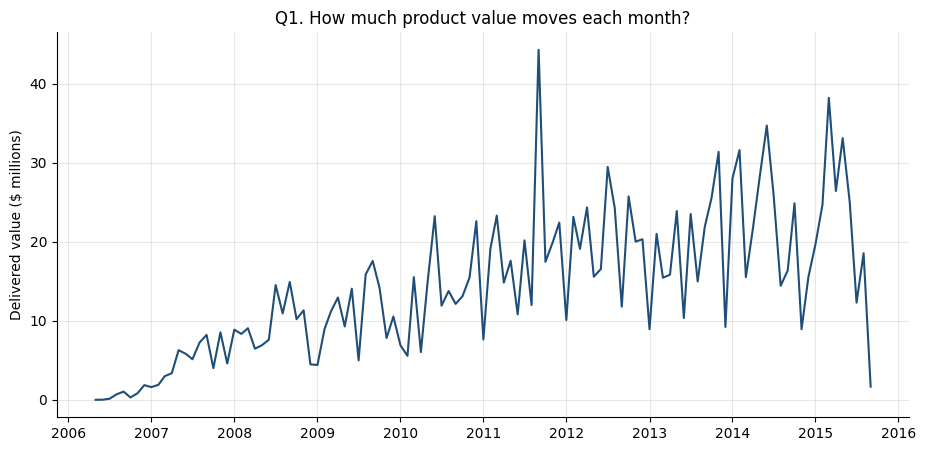

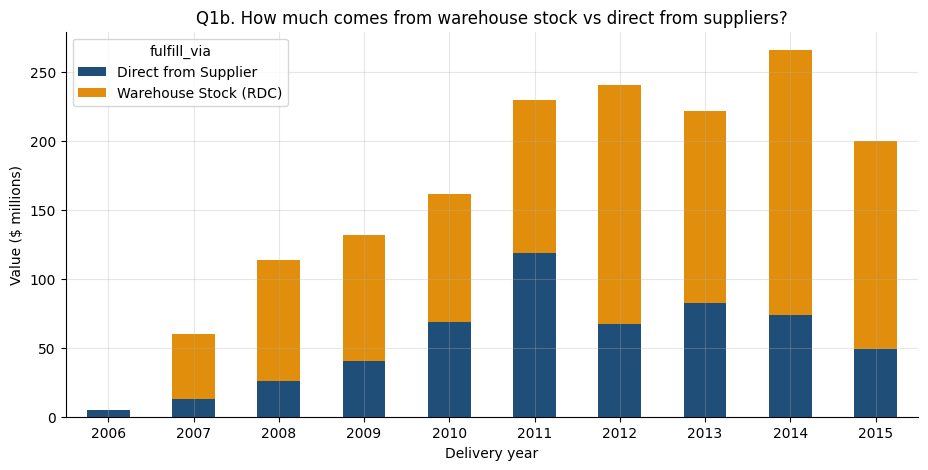

fulfill_via    Direct from Supplier  Warehouse Stock (RDC)
delivery_year                                             
2006                            4.8                    0.1
2007                           12.6                   47.1
2008                           25.5                   88.0
2009                           40.5                   91.2
2010                           68.4                   92.8
2011                          118.3                  111.1
2012                           66.9                  173.4
2013                           82.4                  139.4
2014                           74.0                  191.7
2015                           48.8                  150.7


In [16]:
# Q1. How much stock is moving and how does it change over time? (inventory and stock movement)
monthly_flow = shipment_data.groupby("delivery_month").agg(
    shipment_lines=("shipment_id", "count"),
    units=("quantity", "sum"),
    order_value=("order_value", "sum")).reset_index()

plt.figure()
plt.plot(monthly_flow["delivery_month"], monthly_flow["order_value"] / 1e6, color=main_color, linewidth=1.5)
plt.title("Q1. How much product value moves each month?")
plt.ylabel("Delivered value ($ millions)")
plt.show()

yearly_channel = shipment_data.pivot_table(index="delivery_year", columns="fulfill_via", values="order_value", aggfunc="sum") / 1e6
yearly_channel.plot(kind="bar", stacked=True, color=[main_color, warn_color])
plt.title("Q1b. How much comes from warehouse stock vs direct from suppliers?")
plt.ylabel("Value ($ millions)")
plt.xlabel("Delivery year")
plt.xticks(rotation=0)
plt.show()
print(yearly_channel.round(1))

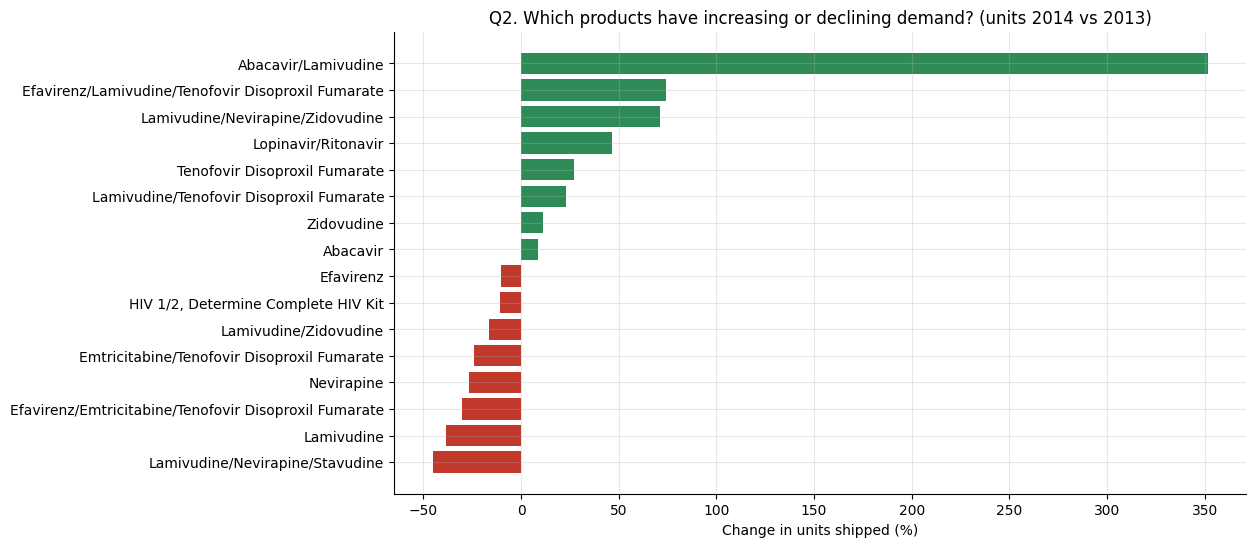

Products compared: 16
Growing: 8   Declining: 8


In [17]:
# Q2. Product demand: which products are growing and which are declining?
# Compare 2013 with 2014 (both complete years)
product_year = shipment_data[shipment_data["delivery_year"].isin([2013, 2014])]
product_demand = product_year.pivot_table(index="product_name", columns="delivery_year", values="quantity", aggfunc="sum").fillna(0)
product_demand.columns = ["units_2013", "units_2014"]
product_demand["total_units"] = product_demand["units_2013"] + product_demand["units_2014"]
product_demand = product_demand[(product_demand["units_2013"] > 0) & (product_demand["total_units"] > 200000)]
product_demand["growth_pct"] = (product_demand["units_2014"] - product_demand["units_2013"]) / product_demand["units_2013"] * 100
product_demand = product_demand.sort_values("growth_pct")

growing_products = product_demand.tail(8)
declining_products = product_demand.head(8)
growth_for_chart = pd.concat([declining_products, growing_products])
growth_bar_colors = []
for growth_value in growth_for_chart["growth_pct"]:
    if growth_value < 0:
        growth_bar_colors.append(bad_color)
    else:
        growth_bar_colors.append(good_color)

plt.figure(figsize=(11, 6))
plt.barh(growth_for_chart.index, growth_for_chart["growth_pct"], color=growth_bar_colors)
plt.title("Q2. Which products have increasing or declining demand? (units 2014 vs 2013)")
plt.xlabel("Change in units shipped (%)")
plt.show()
print("Products compared:", len(product_demand))
print("Growing:", (product_demand["growth_pct"] > 0).sum(), "  Declining:", (product_demand["growth_pct"] < 0).sum())

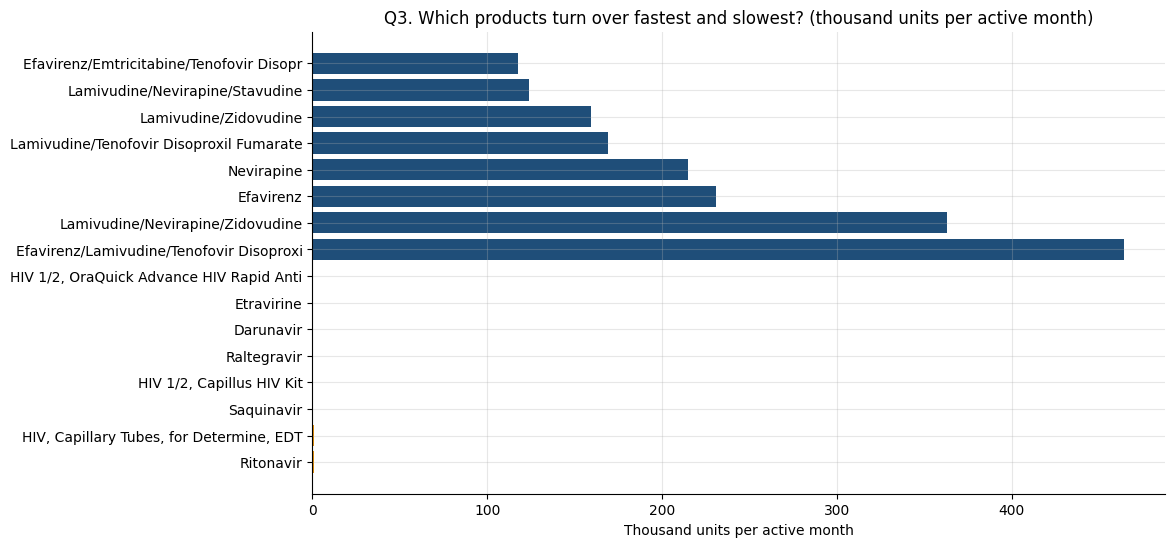

product_group
ARV     1413.2
HRDT     213.3
ACT        0.7
ANTM       0.3
MRDT       0.1
Name: order_value, dtype: float64


In [18]:
# Q3. Demand and turnover: which products move the most and the fastest?
# There are no stock counts in the data, so demand velocity (units per active month) is used as the turnover measure
product_velocity = shipment_data.groupby("product_name").agg(
    total_units=("quantity", "sum"),
    order_value=("order_value", "sum"),
    shipment_lines=("shipment_id", "count"),
    first_delivery=("delivered_date", "min"),
    last_delivery=("delivered_date", "max"),
    active_months=("delivery_month", "nunique")).reset_index()
product_velocity["units_per_active_month"] = product_velocity["total_units"] / product_velocity["active_months"]
product_velocity["lines_per_active_month"] = product_velocity["shipment_lines"] / product_velocity["active_months"]
product_velocity = product_velocity[product_velocity["shipment_lines"] >= 30]
product_velocity = product_velocity.sort_values("units_per_active_month", ascending=False)

fastest_products = product_velocity.head(8)
slowest_products = product_velocity.tail(8)

plt.figure(figsize=(11, 6))
velocity_for_chart = pd.concat([slowest_products, fastest_products])
velocity_bar_colors = [warn_color] * 8 + [main_color] * 8
plt.barh(velocity_for_chart["product_name"].str.slice(0, 40), velocity_for_chart["units_per_active_month"] / 1000, color=velocity_bar_colors)
plt.title("Q3. Which products turn over fastest and slowest? (thousand units per active month)")
plt.xlabel("Thousand units per active month")
plt.show()

product_group_value = shipment_data.groupby("product_group")["order_value"].sum().sort_values(ascending=False) / 1e6
print(product_group_value.round(1))

In [19]:
# Q4. Supplier performance scorecard (direct supplier orders only)
supplier_orders = shipment_data[shipment_data["fulfill_via"] == "Direct from Supplier"]

supplier_scorecard = supplier_orders.groupby("vendor").agg(
    shipment_lines=("shipment_id", "count"),
    order_value=("order_value", "sum"),
    on_time_pct=("is_on_time", "mean"),
    avg_delay_days=("delay_days", "mean"),
    avg_lead_time_days=("lead_time_days", "mean"),
    freight_cost=("freight_cost", "sum")).reset_index()
supplier_scorecard["on_time_pct"] = supplier_scorecard["on_time_pct"] * 100
supplier_scorecard["share_of_spend_pct"] = supplier_scorecard["order_value"] / supplier_scorecard["order_value"].sum() * 100
supplier_scorecard = supplier_scorecard.sort_values("order_value", ascending=False).reset_index(drop=True)
supplier_scorecard["cumulative_share_pct"] = supplier_scorecard["share_of_spend_pct"].cumsum()

# Rating rules: 95% or more on time = Reliable, 90 to 95 = Watch, under 90 = Needs Improvement
# Only suppliers with enough orders (30 or more lines) are judged
supplier_scorecard["reliability_rating"] = "Watch"
supplier_scorecard.loc[supplier_scorecard["on_time_pct"] >= 95, "reliability_rating"] = "Reliable"
supplier_scorecard.loc[supplier_scorecard["on_time_pct"] < 90, "reliability_rating"] = "Needs Improvement"
supplier_scorecard.loc[supplier_scorecard["shipment_lines"] < 30, "reliability_rating"] = "Too Few Orders"
supplier_scorecard = supplier_scorecard.sort_values("order_value", ascending=False).reset_index(drop=True)

print("Suppliers:", len(supplier_scorecard))
print(supplier_scorecard["reliability_rating"].value_counts())
supplier_scorecard.head(12)

Suppliers: 72
reliability_rating
Too Few Orders       52
Reliable             17
Needs Improvement     3
Name: count, dtype: int64


,vendor,shipment_lines,order_value,on_time_pct,avg_delay_days,avg_lead_time_days,freight_cost,share_of_spend_pct,cumulative_share_pct,reliability_rating
0,"Orgenics, Ltd",754,1.477034e+08,87.002653,0.838196,103.226238,9834527.02,27.240885,27.240885,Needs Improvement
1,Aurobindo Pharma Limited,668,9.138371e+07,85.928144,4.411677,130.285047,4950613.50,16.853870,44.094755,Needs Improvement
2,MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORA...,317,7.221367e+07,99.369085,-0.615142,128.299685,3123023.50,13.318345,57.413099,Reliable
3,HETERO LABS LIMITED,277,4.288157e+07,99.277978,-0.209386,128.057762,2641009.83,7.908634,65.321734,Reliable
4,CIPLA LIMITED,175,3.965869e+07,86.857143,4.777143,144.770115,1889796.42,7.314241,72.635975,Needs Improvement
5,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),347,2.944806e+07,98.847262,0.293948,126.268786,1953114.70,5.431097,78.067072,Reliable
6,STRIDES ARCOLAB LIMITED,93,2.248547e+07,95.698925,0.978495,120.478261,1032868.04,4.146988,82.214060,Reliable
7,"Trinity Biotech, Plc",356,2.076934e+07,99.719101,0.084270,101.259366,2321168.85,3.830483,86.044543,Reliable
8,S. BUYS WHOLESALER,715,9.891004e+06,98.461538,-28.678322,34.588595,8887.00,1.824195,87.868738,Reliable
9,"Standard Diagnostics, Inc.",98,8.887046e+06,95.918367,0.255102,100.965909,1291839.63,1.639035,89.507773,Reliable


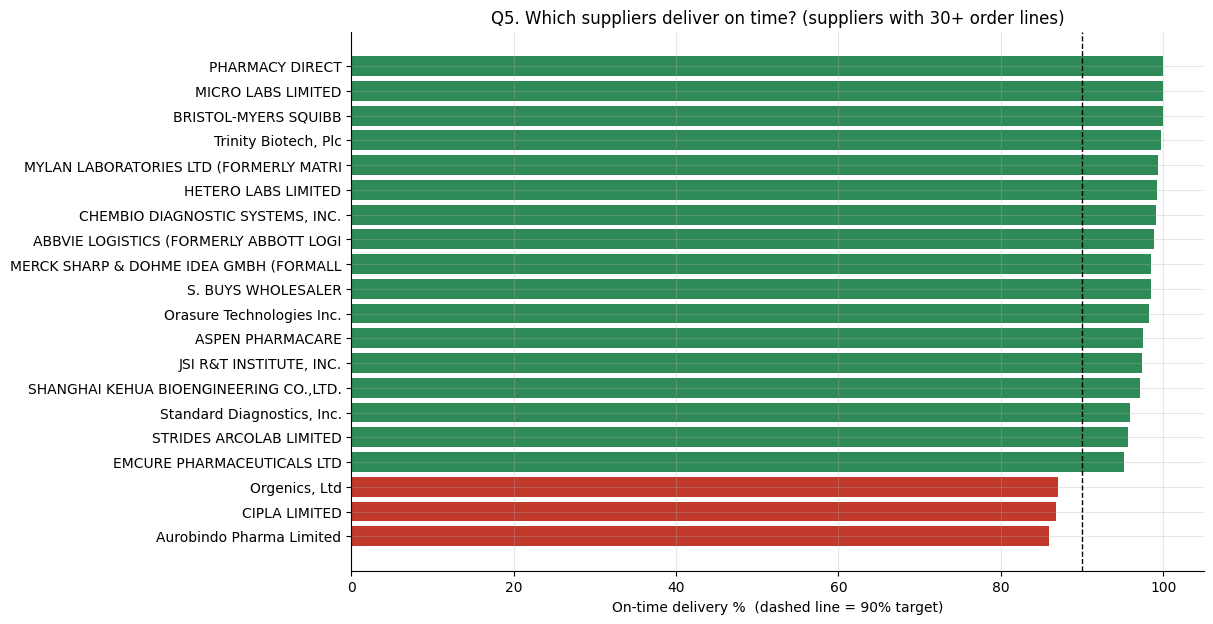

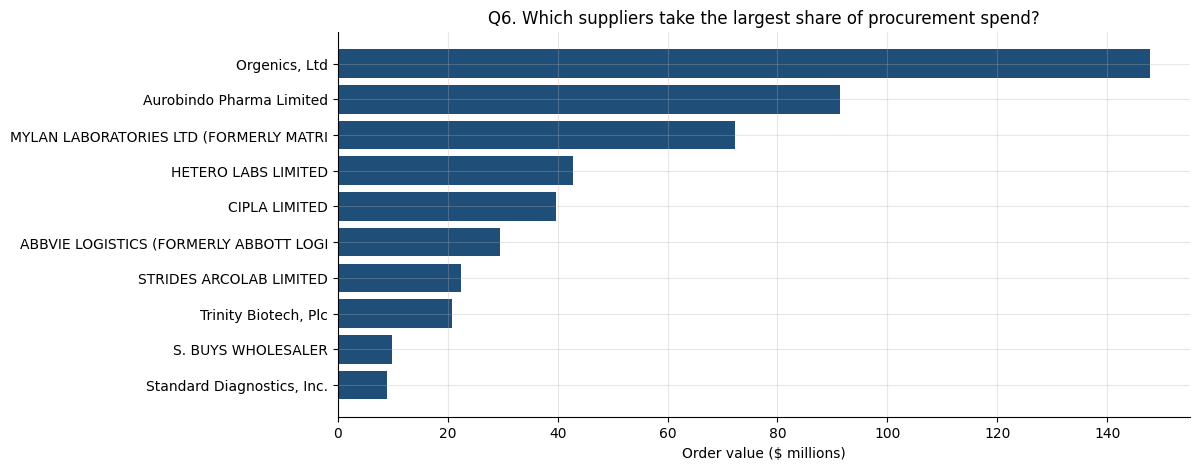

Top 5 suppliers share of spend: 72.6 %
Top 10 suppliers share of spend: 89.5 %


In [20]:
# Q5. Which suppliers deliver on time and which cost the most?
rated_suppliers = supplier_scorecard[supplier_scorecard["shipment_lines"] >= 30].sort_values("on_time_pct")

supplier_bar_colors = []
for reliability_rating in rated_suppliers["reliability_rating"]:
    if reliability_rating == "Reliable":
        supplier_bar_colors.append(good_color)
    elif reliability_rating == "Watch":
        supplier_bar_colors.append(warn_color)
    else:
        supplier_bar_colors.append(bad_color)

plt.figure(figsize=(11, 7))
plt.barh(rated_suppliers["vendor"].str.slice(0, 38), rated_suppliers["on_time_pct"], color=supplier_bar_colors)
plt.axvline(90, color="black", linestyle="--", linewidth=1)
plt.title("Q5. Which suppliers deliver on time? (suppliers with 30+ order lines)")
plt.xlabel("On-time delivery %  (dashed line = 90% target)")
plt.show()

top_ten_spend_suppliers = supplier_scorecard.head(10).sort_values("order_value")
plt.figure(figsize=(11, 5))
plt.barh(top_ten_spend_suppliers["vendor"].str.slice(0, 38), top_ten_spend_suppliers["order_value"] / 1e6, color=main_color)
plt.title("Q6. Which suppliers take the largest share of procurement spend?")
plt.xlabel("Order value ($ millions)")
plt.show()
print("Top 5 suppliers share of spend:", round(supplier_scorecard.head(5)["share_of_spend_pct"].sum(), 1), "%")
print("Top 10 suppliers share of spend:", round(supplier_scorecard.head(10)["share_of_spend_pct"].sum(), 1), "%")

Orders with a lead time: 4587
Average lead time: 105.8 days
Median lead time: 92.0 days


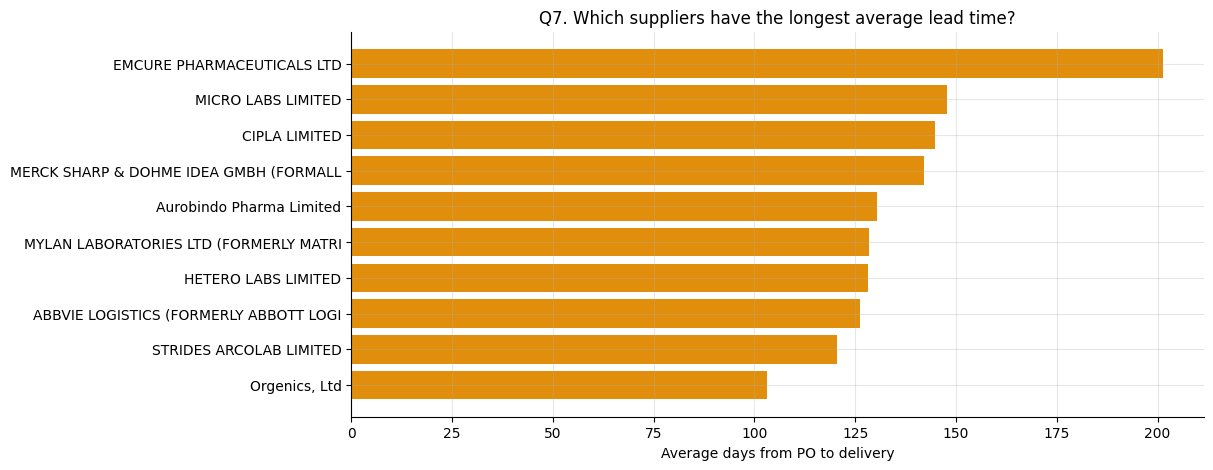


Average lead time by shipment mode (days):
shipment_mode
Air            111.1
Air Charter     80.9
Ocean          176.9
Truck           55.1
Name: lead_time_days, dtype: float64


In [21]:
# Q7. What is the supplier lead time (PO sent to delivery)?
lead_time_data = supplier_orders[supplier_orders["lead_time_days"].notna()]
print("Orders with a lead time:", len(lead_time_data))
print("Average lead time:", round(lead_time_data["lead_time_days"].mean(), 1), "days")
print("Median lead time:", lead_time_data["lead_time_days"].median(), "days")

supplier_lead_times = lead_time_data.groupby("vendor").agg(lines=("shipment_id", "count"), avg_lead_time=("lead_time_days", "mean")).reset_index()
supplier_lead_times = supplier_lead_times[supplier_lead_times["lines"] >= 30].sort_values("avg_lead_time", ascending=False).head(10).sort_values("avg_lead_time")

plt.figure(figsize=(11, 5))
plt.barh(supplier_lead_times["vendor"].str.slice(0, 38), supplier_lead_times["avg_lead_time"], color=warn_color)
plt.title("Q7. Which suppliers have the longest average lead time?")
plt.xlabel("Average days from PO to delivery")
plt.show()

lead_time_by_mode = lead_time_data.groupby("shipment_mode")["lead_time_days"].mean().round(1)
print("\nAverage lead time by shipment mode (days):")
print(lead_time_by_mode)

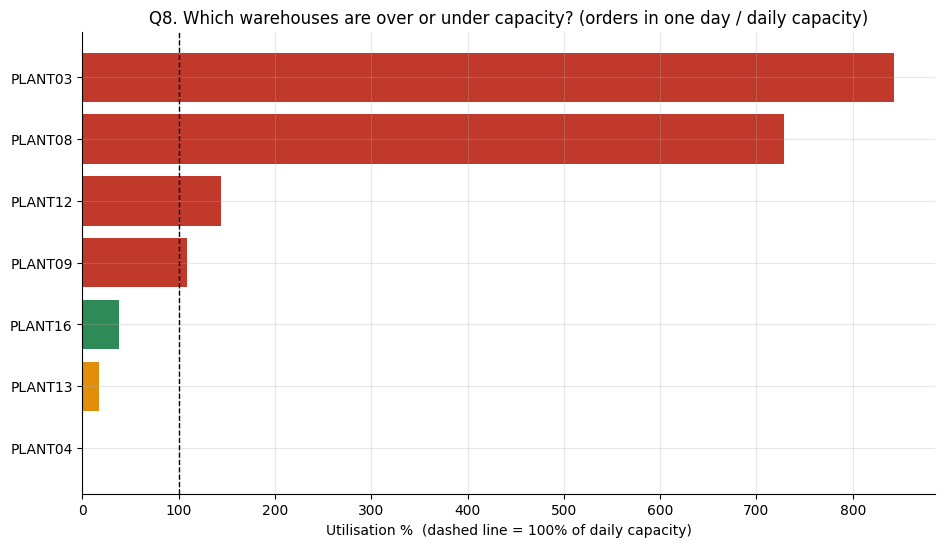

   plant_code  daily_capacity  orders  utilisation_pct  cost_per_unit  handling_cost         capacity_status
0     PLANT03            1013  8541.0            843.1            0.5     14806565.9  Overloaded (over 100%)
1     PLANT08              14   102.0            728.6            0.5       144835.7  Overloaded (over 100%)
2     PLANT12             209   300.0            143.5            0.8        86590.8  Overloaded (over 100%)
3     PLANT09              11    12.0            109.1            0.5       104096.9  Overloaded (over 100%)
4     PLANT16             457   173.0             37.9            1.9       470608.2      Balanced (25-100%)
5     PLANT13             490    86.0             17.6            0.5        20375.4  Under-used (under 25%)
6     PLANT04             554     1.0              0.2            0.4          149.1  Under-used (under 25%)
7     PLANT18             111     0.0              0.0            2.0            0.0  Under-used (under 25%)
8     PLANT17      

In [22]:
# Q8. Warehouse performance: load against capacity and handling cost
plt.figure(figsize=(11, 6))
warehouses_with_orders = warehouse_summary[warehouse_summary["orders"] > 0].sort_values("utilisation_pct")
utilisation_bar_colors = []
for capacity_status in warehouses_with_orders["capacity_status"]:
    if capacity_status.startswith("Overloaded"):
        utilisation_bar_colors.append(bad_color)
    elif capacity_status.startswith("Under"):
        utilisation_bar_colors.append(warn_color)
    else:
        utilisation_bar_colors.append(good_color)
plt.barh(warehouses_with_orders["plant_code"], warehouses_with_orders["utilisation_pct"], color=utilisation_bar_colors)
plt.axvline(100, color="black", linestyle="--", linewidth=1)
plt.title("Q8. Which warehouses are over or under capacity? (orders in one day / daily capacity)")
plt.xlabel("Utilisation %  (dashed line = 100% of daily capacity)")
plt.show()

print(warehouse_summary[["plant_code", "daily_capacity", "orders", "utilisation_pct", "cost_per_unit", "handling_cost", "capacity_status"]].round(1))

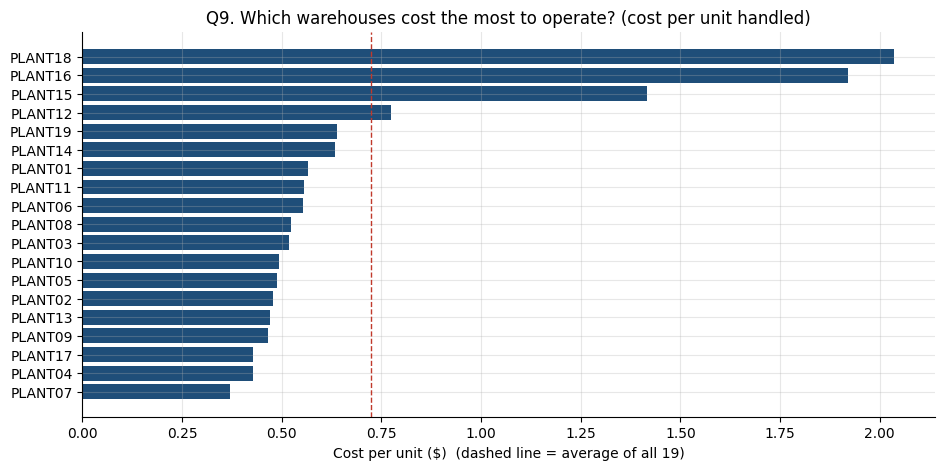

Warehouses that received orders: 7 of 19
Warehouses with no orders on the day: 12
Average cost per unit - all: 0.72
Share of orders handled by the busiest warehouse: 92.7 %


In [23]:
# Q9. Warehouse cost: where is handling most expensive?
plt.figure(figsize=(11, 5))
warehouses_by_cost = warehouse_summary.sort_values("cost_per_unit")
plt.barh(warehouses_by_cost["plant_code"], warehouses_by_cost["cost_per_unit"], color=main_color)
plt.axvline(warehouse_summary["cost_per_unit"].mean(), color=bad_color, linestyle="--", linewidth=1)
plt.title("Q9. Which warehouses cost the most to operate? (cost per unit handled)")
plt.xlabel("Cost per unit ($)  (dashed line = average of all 19)")
plt.show()

busy_warehouses = warehouse_summary[warehouse_summary["orders"] > 0]
print("Warehouses that received orders:", len(busy_warehouses), "of", len(warehouse_summary))
print("Warehouses with no orders on the day:", len(warehouse_summary) - len(busy_warehouses))
print("Average cost per unit - all:", round(warehouse_summary["cost_per_unit"].mean(), 2))
print("Share of orders handled by the busiest warehouse:", round(warehouse_summary["orders"].max() / warehouse_summary["orders"].sum() * 100, 1), "%")

delivery_status
On Time    61.3
Early      27.3
Late       11.5
Name: count, dtype: float64


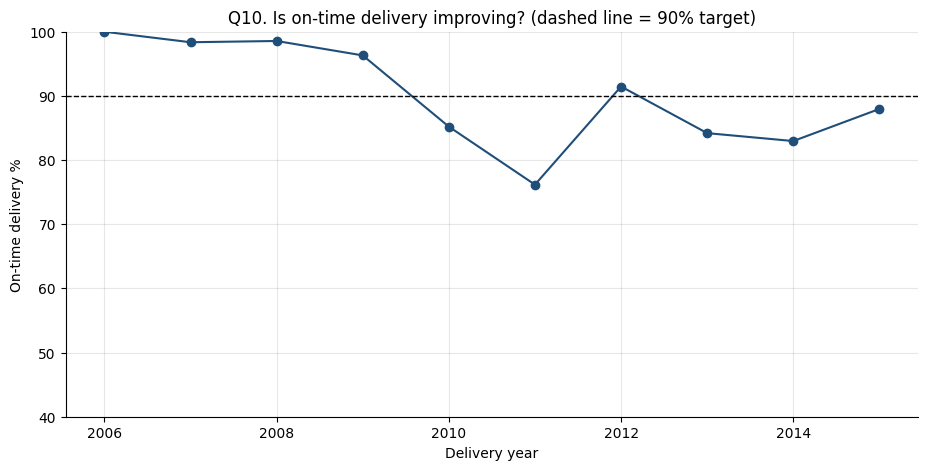

In [24]:
# Q10. Shipment and delivery performance: what percentage is delivered on time?
status_counts = shipment_data["delivery_status"].value_counts()
print((status_counts / len(shipment_data) * 100).round(1))

on_time_by_year = shipment_data.groupby("delivery_year")["is_on_time"].mean() * 100
plt.figure()
plt.plot(on_time_by_year.index, on_time_by_year.values, marker="o", color=main_color)
plt.axhline(90, color="black", linestyle="--", linewidth=1)
plt.title("Q10. Is on-time delivery improving? (dashed line = 90% target)")
plt.ylabel("On-time delivery %")
plt.xlabel("Delivery year")
plt.ylim(40, 100)
plt.show()

                    lines  late_pct  avg_delay
region                                        
Africa               8646      12.6       -6.4
Americas              960       9.6       -6.7
Asia & Middle East    718       0.8       -0.3


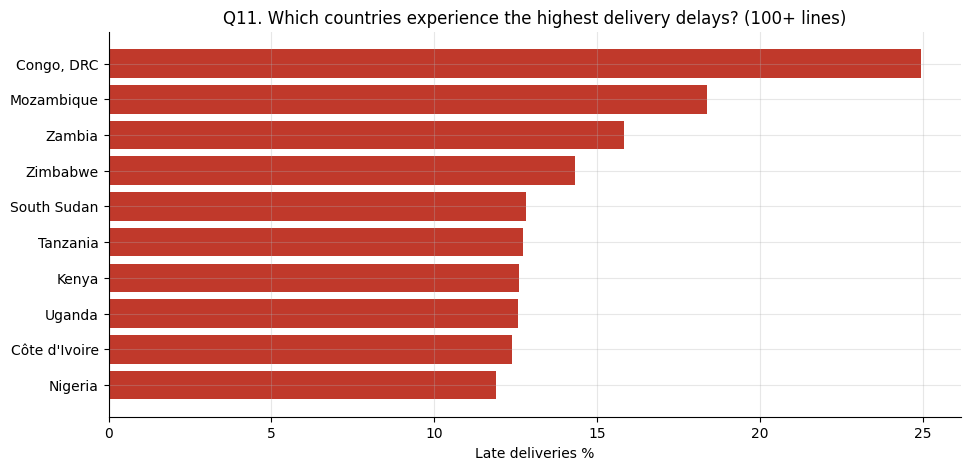

In [25]:
# Q11. Which regions and countries have the worst delivery delays?
region_delay = shipment_data.groupby("region").agg(lines=("shipment_id", "count"), late_pct=("is_late", "mean"), avg_delay=("delay_days", "mean"))
region_delay["late_pct"] = region_delay["late_pct"] * 100
print(region_delay.round(1))

country_delay_table = shipment_data.groupby("country").agg(lines=("shipment_id", "count"), late_pct=("is_late", "mean"), avg_late_days=("delay_days", "mean")).reset_index()
country_delay_table["late_pct"] = country_delay_table["late_pct"] * 100
country_delay_table = country_delay_table[country_delay_table["lines"] >= 100].sort_values("late_pct", ascending=False).head(10).sort_values("late_pct")

plt.figure(figsize=(11, 5))
plt.barh(country_delay_table["country"], country_delay_table["late_pct"], color=bad_color)
plt.title("Q11. Which countries experience the highest delivery delays? (100+ lines)")
plt.xlabel("Late deliveries %")
plt.show()

delay_bucket
On Time or Early     88.5
1-7 days late         4.1
8-30 days late        5.2
Over 30 days late     2.2
Name: count, dtype: float64


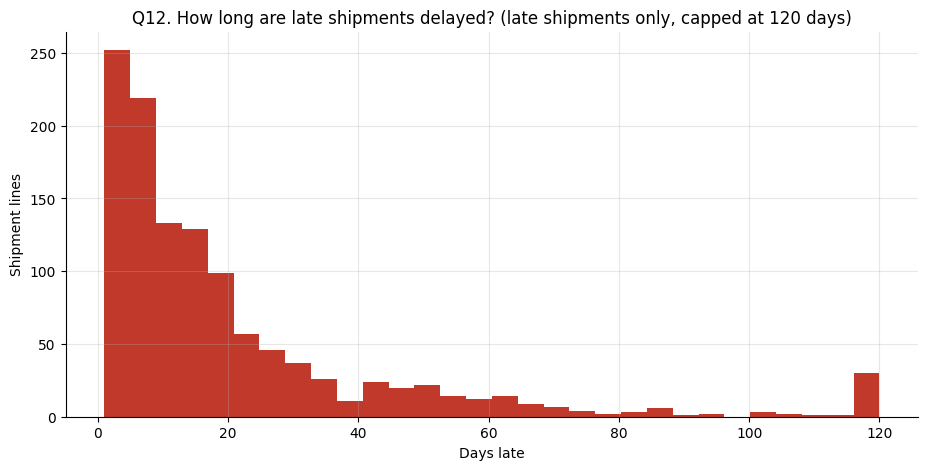

Late shipments: 1186  Average delay: 21.4  Median: 12.0


In [26]:
# Q12. How big are the delays? Delay buckets and distribution
bucket_order = ["On Time or Early", "1-7 days late", "8-30 days late", "Over 30 days late"]
bucket_counts = shipment_data["delay_bucket"].value_counts().reindex(bucket_order)
print((bucket_counts / len(shipment_data) * 100).round(1))

plt.figure()
late_shipments = shipment_data[shipment_data["delay_days"] > 0]
plt.hist(late_shipments["delay_days"].clip(upper=120), bins=30, color=bad_color)
plt.title("Q12. How long are late shipments delayed? (late shipments only, capped at 120 days)")
plt.xlabel("Days late")
plt.ylabel("Shipment lines")
plt.show()
print("Late shipments:", len(late_shipments), " Average delay:", round(late_shipments["delay_days"].mean(), 1), " Median:", late_shipments["delay_days"].median())

  shipment_mode  lines  total_freight  avg_freight_per_line   order_value  weight_kg  avg_lead_delay  late_pct  freight_pct_of_value  freight_per_kg
0           Air   4115    43038623.50              10458.96  5.072595e+08  8163017.0           -1.51      8.94                  8.48            5.26
1   Air Charter    424     8926108.48              21052.14  1.785638e+08  3251372.0          -19.12     12.03                  5.00            2.73
2         Ocean    282     3590728.79              12733.08  1.056238e+08  1939423.0            3.88     15.60                  3.40            1.85
3         Truck   1166    11865688.23              10176.41  3.688590e+08  7442279.0          -10.14     23.93                  3.22            1.59


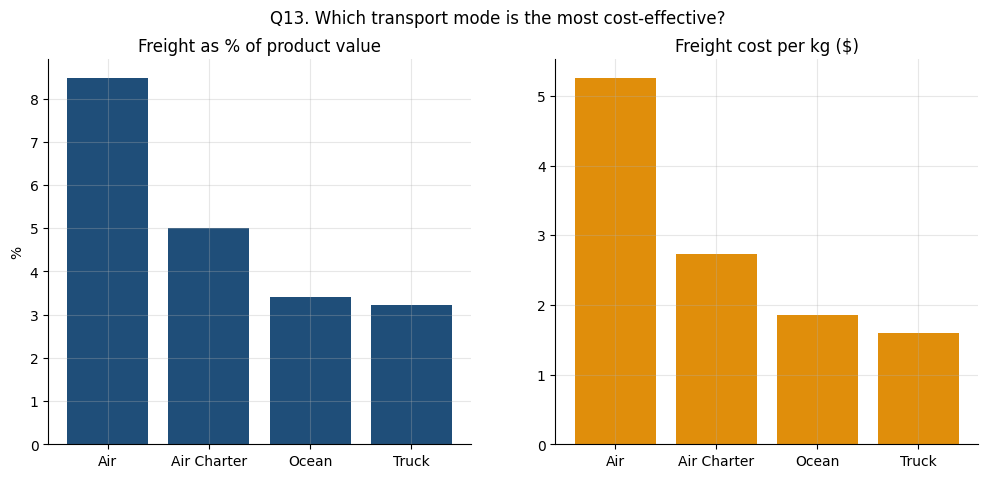

In [27]:
# Q13. Transportation cost: which shipment mode is the most cost-effective?
freight_data = shipment_data[shipment_data["freight_status"] == "Freight Recorded"]
mode_cost = freight_data.groupby("shipment_mode").agg(
    lines=("shipment_id", "count"),
    total_freight=("freight_cost", "sum"),
    avg_freight_per_line=("freight_cost", "mean"),
    order_value=("order_value", "sum"),
    weight_kg=("weight_kg", "sum"),
    avg_lead_delay=("delay_days", "mean"),
    late_pct=("is_late", "mean")).reset_index()
mode_cost["freight_pct_of_value"] = mode_cost["total_freight"] / mode_cost["order_value"] * 100
mode_cost["late_pct"] = mode_cost["late_pct"] * 100

# Freight per kg only where weight is known
weight_known = freight_data[freight_data["weight_kg"] > 0]
freight_by_mode_with_weight = weight_known.groupby("shipment_mode")["freight_cost"].sum()
weight_by_mode_with_weight = weight_known.groupby("shipment_mode")["weight_kg"].sum()
cost_per_kg_by_mode = freight_by_mode_with_weight / weight_by_mode_with_weight
mode_cost["freight_per_kg"] = mode_cost["shipment_mode"].map(cost_per_kg_by_mode)
print(mode_cost.round(2))

chart_figure, chart_axes = plt.subplots(1, 2, figsize=(12, 5))
chart_axes[0].bar(mode_cost["shipment_mode"], mode_cost["freight_pct_of_value"], color=main_color)
chart_axes[0].set_title("Freight as % of product value")
chart_axes[0].set_ylabel("%")
chart_axes[1].bar(mode_cost["shipment_mode"], mode_cost["freight_per_kg"], color=warn_color)
chart_axes[1].set_title("Freight cost per kg ($)")
plt.suptitle("Q13. Which transport mode is the most cost-effective?")
plt.show()

  shipment_mode  lines  on_time  avg_delay
0           Air   6113     90.4       -3.8
1   Air Charter    650     88.5      -19.0
2         Ocean    371     82.5        5.9
3         Truck   2830     83.9       -9.9


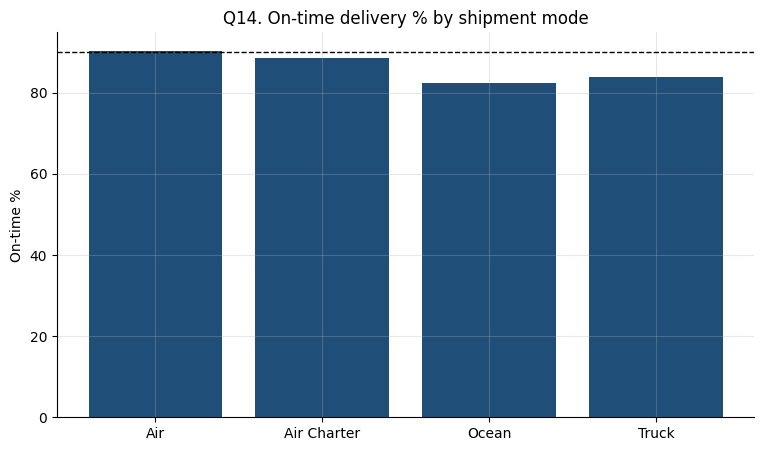

        inco_term  lines  total_freight  order_value  freight_pct_of_value
1             CIP    163      1170620.7   27109565.1                   4.3
3             DDP    303      2499186.5   87988445.5                   2.8
5             EXW   2167     28248651.2  326265225.1                   8.7
6             FCA    352      2039273.4   27653391.2                   7.4
7  N/A - From RDC   3205     34854520.4  719976364.1                   4.8


In [28]:
# Q14. Does a more expensive mode deliver on time more often?
mode_status = shipment_data.groupby("shipment_mode").agg(lines=("shipment_id", "count"), on_time=("is_on_time", "mean"), avg_delay=("delay_days", "mean")).reset_index()
mode_status["on_time"] = mode_status["on_time"] * 100
print(mode_status.round(1))

plt.figure(figsize=(9, 5))
plt.bar(mode_status["shipment_mode"], mode_status["on_time"], color=main_color)
plt.axhline(90, color="black", linestyle="--", linewidth=1)
plt.title("Q14. On-time delivery % by shipment mode")
plt.ylabel("On-time %")
plt.show()

# Incoterms (who pays for freight) against freight share
inco_cost = freight_data.groupby("inco_term").agg(lines=("shipment_id", "count"), total_freight=("freight_cost", "sum"), order_value=("order_value", "sum")).reset_index()
inco_cost["freight_pct_of_value"] = inco_cost["total_freight"] / inco_cost["order_value"] * 100
print(inco_cost[inco_cost["lines"] >= 30].round(1))

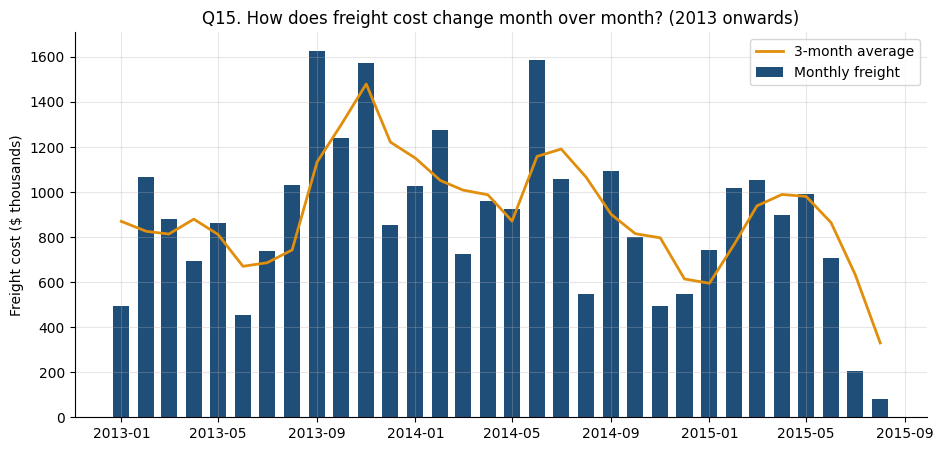

Largest monthly increase since 2013 (%): 115.6
Largest monthly drop since 2013 (%): -71.1
Average monthly freight since 2013: $ 882919
               total_freight  order_value  freight_pct_of_value
delivery_year                                                  
2006                287018.7    3461747.3                   8.3
2007               2940323.6   39923190.4                   7.4
2008               5301838.0   83087814.0                   6.4
2009               4967509.4  106402730.5                   4.7
2010               7120701.8  115865025.8                   6.1
2011               8900745.0  187187943.6                   4.8
2012              11046320.6  181724068.0                   6.1
2013              11515896.8  169488064.4                   6.8
2014              11045102.9  187655484.8                   5.9
2015               5692392.5  114321946.8                   5.0


In [29]:
# Q15. How do transportation costs change month over month?
monthly_freight = freight_data.groupby("delivery_month").agg(total_freight=("freight_cost", "sum"), lines=("shipment_id", "count")).reset_index()
monthly_freight = monthly_freight.sort_values("delivery_month")
monthly_freight["mom_change_pct"] = monthly_freight["total_freight"].pct_change() * 100
monthly_freight["rolling_3_month"] = monthly_freight["total_freight"].rolling(3).mean()

monthly_freight_recent = monthly_freight[monthly_freight["delivery_month"] >= "2013-01-01"]
plt.figure()
plt.bar(monthly_freight_recent["delivery_month"], monthly_freight_recent["total_freight"] / 1000, width=20, color=main_color, label="Monthly freight")
plt.plot(monthly_freight_recent["delivery_month"], monthly_freight_recent["rolling_3_month"] / 1000, color=warn_color, linewidth=2, label="3-month average")
plt.title("Q15. How does freight cost change month over month? (2013 onwards)")
plt.ylabel("Freight cost ($ thousands)")
plt.legend()
plt.show()

# Early months (2006 to 2007) have tiny volumes, so month-over-month % is only read from 2013 onwards
print("Largest monthly increase since 2013 (%):", round(monthly_freight_recent["mom_change_pct"].max(), 1))
print("Largest monthly drop since 2013 (%):", round(monthly_freight_recent["mom_change_pct"].min(), 1))
print("Average monthly freight since 2013: $", round(monthly_freight_recent["total_freight"].mean()))
yearly_freight = freight_data.groupby("delivery_year").agg(total_freight=("freight_cost", "sum"), order_value=("order_value", "sum"))
yearly_freight["freight_pct_of_value"] = yearly_freight["total_freight"] / yearly_freight["order_value"] * 100
print(yearly_freight.round(1))

capacity_status
Under-used (under 25%)    14
Overloaded (over 100%)     4
Balanced (25-100%)         1
Name: count, dtype: int64

Overloaded warehouses: ['PLANT03', 'PLANT08', 'PLANT12', 'PLANT09']
Under-used warehouses: ['PLANT13', 'PLANT04', 'PLANT18', 'PLANT17', 'PLANT15', 'PLANT05', 'PLANT14', 'PLANT07', 'PLANT10', 'PLANT06', 'PLANT02', 'PLANT01', 'PLANT11', 'PLANT19']
Unused capacity (orders/day) in warehouses that got no orders: 3043


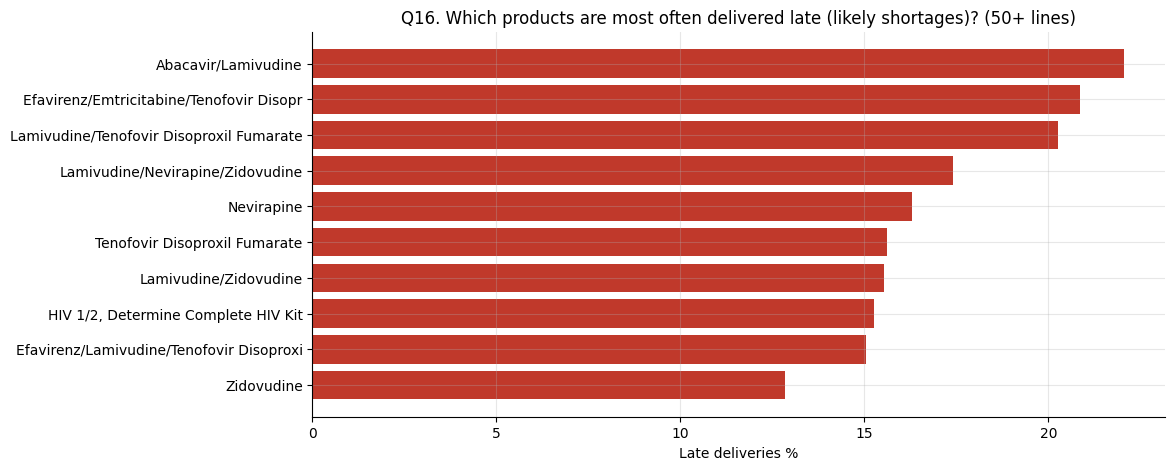

In [30]:
# Q16. Stock-out and overstock risk: where is capacity short or wasted?
# No stock counts exist in these data, so capacity pressure and late shipments are used as the signal:
#   Overloaded warehouse = orders above what it can process in a day (backlog, shortage risk)
#   Under-used warehouse = capacity sitting idle (excess stock and fixed cost risk)
print(warehouse_summary["capacity_status"].value_counts())
overloaded = warehouse_summary[warehouse_summary["capacity_status"].str.startswith("Overloaded")]
underused = warehouse_summary[warehouse_summary["capacity_status"].str.startswith("Under")]
print("\nOverloaded warehouses:", list(overloaded["plant_code"]))
print("Under-used warehouses:", list(underused["plant_code"]))
print("Unused capacity (orders/day) in warehouses that got no orders:", warehouse_summary.loc[warehouse_summary["orders"] == 0, "daily_capacity"].sum())

# Products most often shipped late = the ones with supply shortages
product_late_table = shipment_data.groupby("product_name").agg(lines=("shipment_id", "count"), late_pct=("is_late", "mean"), avg_delay=("delay_days", "mean")).reset_index()
product_late_table["late_pct"] = product_late_table["late_pct"] * 100
product_late_table = product_late_table[product_late_table["lines"] >= 50].sort_values("late_pct", ascending=False).head(10).sort_values("late_pct")

plt.figure(figsize=(11, 5))
plt.barh(product_late_table["product_name"].str.slice(0, 40), product_late_table["late_pct"], color=bad_color)
plt.title("Q16. Which products are most often delivered late (likely shortages)? (50+ lines)")
plt.xlabel("Late deliveries %")
plt.show()

             fulfill_via  lines  on_time_pct  late_pct  avg_delay  avg_value
0   Direct from Supplier   4920         94.7       5.3       -3.5   110205.7
1  Warehouse Stock (RDC)   5404         82.8      17.2       -8.3   200846.1


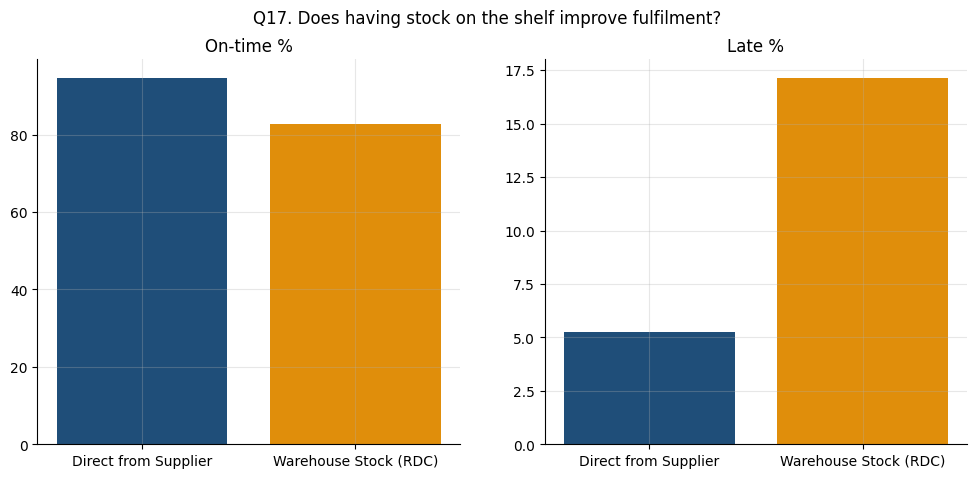

            late_pct  avg_delay
order_size                     
Small            6.8       -7.8
Medium          10.1       -6.0
Large           12.4       -5.3
Very large      16.6       -5.1

Correlation of order value with delay days: -0.016


In [31]:
# Q17. Relationship between stock availability and order fulfilment
# Warehouse stock (RDC) = items already on the shelf. Direct = ordered from the supplier on demand.
channel_performance = shipment_data.groupby("fulfill_via").agg(
    lines=("shipment_id", "count"),
    on_time_pct=("is_on_time", "mean"),
    late_pct=("is_late", "mean"),
    avg_delay=("delay_days", "mean"),
    avg_value=("order_value", "mean")).reset_index()
channel_performance["on_time_pct"] = channel_performance["on_time_pct"] * 100
channel_performance["late_pct"] = channel_performance["late_pct"] * 100
print(channel_performance.round(1))

chart_figure, chart_axes = plt.subplots(1, 2, figsize=(12, 5))
chart_axes[0].bar(channel_performance["fulfill_via"], channel_performance["on_time_pct"], color=[main_color, warn_color])
chart_axes[0].set_title("On-time %")
chart_axes[1].bar(channel_performance["fulfill_via"], channel_performance["late_pct"], color=[main_color, warn_color])
chart_axes[1].set_title("Late %")
plt.suptitle("Q17. Does having stock on the shelf improve fulfilment?")
plt.show()

# Do bigger orders get delayed more?
shipment_data["order_size"] = pd.qcut(shipment_data["order_value"], 4, labels=["Small", "Medium", "Large", "Very large"])
shipment_data["order_size_order"] = shipment_data["order_size"].cat.codes + 1
size_performance = shipment_data.groupby("order_size").agg(late_pct=("is_late", "mean"), avg_delay=("delay_days", "mean"))
size_performance["late_pct"] = size_performance["late_pct"] * 100
print(size_performance.round(1))
print("\nCorrelation of order value with delay days:", round(shipment_data["order_value"].corr(shipment_data["delay_days"]), 3))

  carrier  orders  late_pct  avg_ship_ahead  avg_transit_days     units
0  V444_0    6264      2.92            1.67              2.00  23613389
1  V444_1    2097      0.43            2.33              1.05   2089040
2   V44_3     854      0.00            2.02              1.29   3810886
        service_level_name  orders  late_pct  avg_transit_days
0  CRF (Customer Referred)     854      0.00              1.29
1       DTD (Door to Door)    2143      0.42              1.09
2       DTP (Door to Port)    6218      2.94              1.99


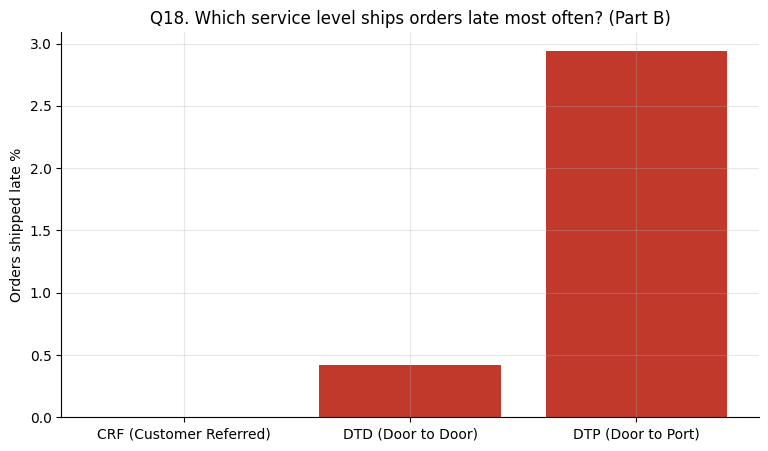

In [32]:
# Q18. Part B: order fulfilment by carrier and service level
carrier_performance = plant_orders.groupby("carrier").agg(
    orders=("order_id", "count"),
    late_pct=("is_shipped_late", "mean"),
    avg_ship_ahead=("ship_ahead_days", "mean"),
    avg_transit_days=("transit_days", "mean"),
    units=("units", "sum")).reset_index()
carrier_performance["late_pct"] = carrier_performance["late_pct"] * 100
print(carrier_performance.round(2))

service_performance = plant_orders.groupby("service_level_name").agg(
    orders=("order_id", "count"),
    late_pct=("is_shipped_late", "mean"),
    avg_transit_days=("transit_days", "mean")).reset_index()
service_performance["late_pct"] = service_performance["late_pct"] * 100
print(service_performance.round(2))

plt.figure(figsize=(9, 5))
plt.bar(service_performance["service_level_name"], service_performance["late_pct"], color=bad_color)
plt.title("Q18. Which service level ships orders late most often? (Part B)")
plt.ylabel("Orders shipped late %")
plt.show()

In [33]:
# Q19. Which suppliers and warehouses need operational improvement?
needs_improvement_suppliers = supplier_scorecard[(supplier_scorecard["shipment_lines"] >= 30) & (supplier_scorecard["reliability_rating"] == "Needs Improvement")]
print("SUPPLIERS BELOW 90% ON TIME")
print(needs_improvement_suppliers[["vendor", "shipment_lines", "order_value", "on_time_pct", "avg_delay_days", "avg_lead_time_days"]].round(1).to_string(index=False))

print("\nWAREHOUSES NEEDING ATTENTION")
attention_warehouses = warehouse_summary[(warehouse_summary["utilisation_pct"] > 100) | ((warehouse_summary["cost_per_unit"] > 1) & (warehouse_summary["orders"] > 0))]
print(attention_warehouses[["plant_code", "daily_capacity", "orders", "utilisation_pct", "cost_per_unit", "capacity_status"]].round(1).to_string(index=False))

SUPPLIERS BELOW 90% ON TIME
                  vendor  shipment_lines  order_value  on_time_pct  avg_delay_days  avg_lead_time_days
           Orgenics, Ltd             754  147703351.0         87.0             0.8               103.2
Aurobindo Pharma Limited             668   91383710.7         85.9             4.4               130.3
           CIPLA LIMITED             175   39658694.6         86.9             4.8               144.8

WAREHOUSES NEEDING ATTENTION
plant_code  daily_capacity  orders  utilisation_pct  cost_per_unit        capacity_status
   PLANT03            1013  8541.0            843.1            0.5 Overloaded (over 100%)
   PLANT08              14   102.0            728.6            0.5 Overloaded (over 100%)
   PLANT12             209   300.0            143.5            0.8 Overloaded (over 100%)
   PLANT09              11    12.0            109.1            0.5 Overloaded (over 100%)
   PLANT16             457   173.0             37.9            1.9     Balanced 

In [34]:
# Step 15: findings and recommendations (numbers come from the analysis above)
slowest_mode = mode_cost.sort_values("late_pct", ascending=False).iloc[0]
cheapest_mode = mode_cost.sort_values("freight_per_kg").iloc[0]
dearest_mode = mode_cost.sort_values("freight_per_kg").iloc[-1]
worst_region = region_delay.sort_values("late_pct", ascending=False).index[0]
weak_suppliers = supplier_scorecard[(supplier_scorecard["shipment_lines"] >= 30) & (supplier_scorecard["reliability_rating"] == "Needs Improvement")]
weak_supplier_spend = weak_suppliers["share_of_spend_pct"].sum()
busiest_warehouse = warehouse_summary.iloc[0]
idle_warehouse_count = (warehouse_summary["orders"] == 0).sum()

print("KEY FINDINGS")
print("1. On-time delivery is", round(overall_on_time_pct, 1), "% and late shipments run", round(average_delay_of_late, 1), "days late on average.")
print("2. Suppliers below 90% on time:", len(weak_suppliers), "- together they hold", round(weak_supplier_spend, 1), "% of procurement spend.")
print("3. Average supplier lead time is", round(average_lead_time, 1), "days; ocean is the slowest mode.")
print("4.", worst_region, "has the highest late rate at", round(region_delay.loc[worst_region, "late_pct"], 1), "%.")
print("5. Cheapest mode per kg:", cheapest_mode["shipment_mode"], "($", round(cheapest_mode["freight_per_kg"], 2), "). Most expensive:", dearest_mode["shipment_mode"], "($", round(dearest_mode["freight_per_kg"], 2), ").")
print("6.", slowest_mode["shipment_mode"], "freight has the highest late rate at", round(slowest_mode["late_pct"], 1), "% (lines with freight recorded).")
print("7. Warehouse stock (RDC) is on time", round(channel_performance.loc[1, "on_time_pct"], 1), "% vs", round(channel_performance.loc[0, "on_time_pct"], 1), "% for direct supplier orders.")
print("8.", busiest_warehouse["plant_code"], "ran at", round(busiest_warehouse["utilisation_pct"]), "% of daily capacity while", idle_warehouse_count, "warehouses received no orders.")
print("")
print("RECOMMENDATIONS")
print("1. Put the weakest suppliers on a performance plan with penalties for late delivery and a 90% on-time target.")
print("2. Spread spend away from the top 5 suppliers (", round(supplier_scorecard.head(5)["share_of_spend_pct"].sum(), 1), "% of spend) by qualifying second sources.")
print("3. Move orders from the overloaded warehouse to under-used warehouses with spare daily capacity.")
print("4. Use ocean or truck for non-urgent, heavy shipments and keep air for urgent items to cut freight per kg.")
print("5. Raise safety stock for items that are often late so warehouse stock stays above 90% on time.")
print("6. Track freight cost per kg and late % monthly with the dashboard and review the top 3 delayed countries each quarter.")

KEY FINDINGS
1. On-time delivery is 88.5 % and late shipments run 21.4 days late on average.
2. Suppliers below 90% on time: 3 - together they hold 51.4 % of procurement spend.
3. Average supplier lead time is 105.8 days; ocean is the slowest mode.
4. Africa has the highest late rate at 12.6 %.
5. Cheapest mode per kg: Truck ($ 1.59 ). Most expensive: Air ($ 5.26 ).
6. Truck freight has the highest late rate at 23.9 % (lines with freight recorded).
7. Warehouse stock (RDC) is on time 82.8 % vs 94.7 % for direct supplier orders.
8. PLANT03 ran at 843 % of daily capacity while 12 warehouses received no orders.

RECOMMENDATIONS
1. Put the weakest suppliers on a performance plan with penalties for late delivery and a 90% on-time target.
2. Spread spend away from the top 5 suppliers ( 72.6 % of spend) by qualifying second sources.
3. Move orders from the overloaded warehouse to under-used warehouses with spare daily capacity.
4. Use ocean or truck for non-urgent, heavy shipments and keep ai

In [35]:
# Step 16: export clean tables for Power BI (PowerBI_Data folder)
output_folder = "PowerBI_Data/"

# Date table covering every delivery month
date_table = pd.DataFrame({"date": pd.date_range("2006-01-01", "2015-12-31", freq="D")})
date_table["year"] = date_table["date"].dt.year
date_table["quarter"] = "Q" + date_table["date"].dt.quarter.astype(str)
date_table["month_number"] = date_table["date"].dt.month
date_table["month_name"] = date_table["date"].dt.strftime("%b")
date_table["year_month"] = date_table["date"].dt.strftime("%Y-%m")
date_table["month_start"] = date_table["date"].dt.to_period("M").dt.to_timestamp()
date_table.to_csv(output_folder + "Dim_Date.csv", index=False)

# Main shipment fact table
fact_shipments = shipment_data[["shipment_id", "project_code", "po_number", "asn_number", "country", "region",
                                "fulfill_via", "inco_term", "shipment_mode", "product_group", "sub_classification",
                                "vendor", "product_name", "brand", "dosage_form", "manufacturing_site",
                                "quantity", "order_value", "unit_price", "weight_kg", "freight_cost",
                                "freight_status", "freight_per_kg", "freight_pct_of_value", "insurance_cost",
                                "po_sent_date", "scheduled_date", "delivered_date", "delay_days",
                                "delivery_status", "delay_bucket", "delay_bucket_order", "order_size", "order_size_order", "is_on_time", "is_late",
                                "lead_time_days", "delivery_year", "delivery_month"]].copy()
fact_shipments["delivery_month"] = fact_shipments["delivery_month"].dt.date
fact_shipments.to_csv(output_folder + "Fact_Shipments.csv", index=False)

# Supplier, product, country and warehouse tables
supplier_scorecard.to_csv(output_folder + "Dim_Supplier.csv", index=False)
product_velocity.to_csv(output_folder + "Product_Velocity.csv", index=False)
country_table = shipment_data.groupby(["country", "region"]).agg(lines=("shipment_id", "count")).reset_index()
country_table[["country", "region"]].to_csv(output_folder + "Dim_Country.csv", index=False)
warehouse_summary.to_csv(output_folder + "Dim_Warehouse.csv", index=False)
fact_plant_orders = plant_orders[["order_id", "order_date", "origin_port", "carrier", "transit_days",
                                  "service_level", "service_level_name", "ship_ahead_days", "ship_late_days",
                                  "is_shipped_late", "customer", "product_id", "plant_code", "units",
                                  "weight_kg", "cost_per_unit", "handling_cost"]]
fact_plant_orders.to_csv(output_folder + "Fact_Warehouse_Orders.csv", index=False)
monthly_freight.to_csv(output_folder + "Monthly_Freight.csv", index=False)
mode_cost.to_csv(output_folder + "Mode_Cost_Summary.csv", index=False)

print("Exported to", output_folder)
print("Shipment fact rows:", len(fact_shipments), " Warehouse order rows:", len(fact_plant_orders))

Exported to PowerBI_Data/
Shipment fact rows: 10324  Warehouse order rows: 9215


In [36]:
# Step 17: Excel workbook with the supporting tables
with pd.ExcelWriter("Logistics_Analysis.xlsx") as excel_writer:
    preparation_summary.to_excel(excel_writer, sheet_name="Data_Preparation", index=False)
    supplier_scorecard.to_excel(excel_writer, sheet_name="Supplier_Scorecard", index=False)
    warehouse_summary.to_excel(excel_writer, sheet_name="Warehouse_Performance", index=False)
    mode_cost.to_excel(excel_writer, sheet_name="Transport_Cost_By_Mode", index=False)
    monthly_freight.to_excel(excel_writer, sheet_name="Monthly_Freight", index=False)
    region_delay.reset_index().to_excel(excel_writer, sheet_name="Region_Delays", index=False)
    product_velocity.to_excel(excel_writer, sheet_name="Product_Velocity", index=False)
    product_demand.reset_index().to_excel(excel_writer, sheet_name="Demand_Growth", index=False)
    channel_performance.to_excel(excel_writer, sheet_name="Stock_vs_Direct", index=False)
    carrier_performance.to_excel(excel_writer, sheet_name="Carrier_Performance", index=False)
print("Excel workbook saved")

Excel workbook saved
